# Comparative Study of Text Classification Algorithms
## Decision Tree vs K-Nearest Neighbours (KNN) vs Support Vector Machine (SVM) vs Naïve Bayes

**Dataset:** UCI SMS Spam Collection  
**Problem:** Classify an SMS message as `ham` (legitimate) or `spam` (unwanted).



## 1. Study objectives

1. Load a labelled real-world text dataset.
2. Clean and preprocess the SMS messages.
3. Convert messages into numerical TF-IDF features.
4. Train four classifiers using the same train/test split and feature matrix.
5. Evaluate them using Accuracy, Precision, Recall and F1-score.
6. inspect confusion matrices and compare the models.
7. Perform a what-if experiment by changing the SVM parameter `C`.

### Class definitions

- **ham:** A normal, legitimate SMS message.
- **spam:** An unwanted or unsolicited SMS message.

The positive class for Precision, Recall and F1-score is **spam**. This is important because missing a spam message (false negative) may be undesirable.

In [1]:
import re
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

RANDOM_STATE = 42
print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
dataset_url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
zip_path = Path("/content/sms_spam_collection.zip")
extract_dir = Path("/content/sms_spam_data")
extract_dir.mkdir(exist_ok=True)

urllib.request.urlretrieve(dataset_url, zip_path)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_dir)

data_file = extract_dir / "SMSSpamCollection"
if not data_file.exists():
    # Find the data file in case the archive layout changes.
    matches = list(extract_dir.rglob("SMSSpamCollection"))
    if not matches:
        raise FileNotFoundError("Could not find SMSSpamCollection in the downloaded archive.")
    data_file = matches[0]

df = pd.read_csv(
    data_file,
    sep="\t",
    header=None,
    names=["label", "message"],
    encoding="utf-8"
)

print("Dataset downloaded and loaded successfully.")
print("Dataset shape:", df.shape)
display(df.head())

Dataset downloaded and loaded successfully.
Dataset shape: (5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None

Missing values:
label      0
message    0
dtype: int64

Class counts:
label
ham     4825
spam     747
Name: count, dtype: int64

Class percentages:


,percentage
label,
ham,86.59
spam,13.41


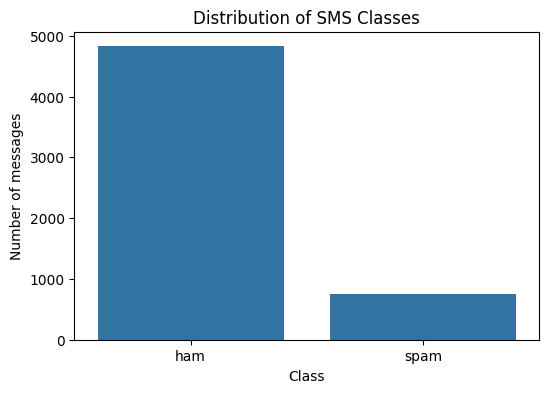

In [3]:
print("Dataset information:")
print(df.info())

print("\nMissing values:")
print(df.isnull().sum())

print("\nClass counts:")
print(df["label"].value_counts())

print("\nClass percentages:")
display((df["label"].value_counts(normalize=True) * 100).round(2).rename("percentage"))

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="label")
plt.title("Distribution of SMS Classes")
plt.xlabel("Class")
plt.ylabel("Number of messages")
plt.show()

In [4]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"\S+@\S+", " ", text)
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df = df.dropna(subset=["label", "message"]).copy()
df["clean_message"] = df["message"].apply(clean_text)

# Remove exact duplicate messages to reduce the chance of identical
# messages appearing in both training and testing sets.
before = len(df)
df = df.drop_duplicates(subset=["label", "clean_message"]).reset_index(drop=True)

print("Rows before duplicate removal:", before)
print("Rows after duplicate removal:", len(df))
display(df[["label", "message", "clean_message"]].head(10))

Rows before duplicate removal: 5572
Rows after duplicate removal: 5125


,label,message,clean_message
0,ham,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...
1,ham,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in 2 a wkly comp to win fa cup fina...
3,ham,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,ham,"Nah I don't think he goes to usf, he lives aro...",nah i don t think he goes to usf he lives arou...
5,spam,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey there darling it s been 3 week s n...
6,ham,Even my brother is not like to speak with me. ...,even my brother is not like to speak with me t...
7,ham,As per your request 'Melle Melle (Oru Minnamin...,as per your request melle melle oru minnaminun...
8,spam,WINNER!! As a valued network customer you have...,winner as a valued network customer you have b...
9,spam,Had your mobile 11 months or more? U R entitle...,had your mobile 11 months or more u r entitled...


In [5]:
X_text = df["clean_message"]
y = df["label"].map({"ham": 0, "spam": 1})

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training messages:", len(X_train_text))
print("Testing messages:", len(X_test_text))
print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True).rename("proportion").round(3))
print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True).rename("proportion").round(3))

Training messages: 4100
Testing messages: 1025

Training class distribution:
label
0    0.878
1    0.122
Name: proportion, dtype: float64

Testing class distribution:
label
0    0.878
1    0.122
Name: proportion, dtype: float64


In [6]:
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

X_train = tfidf.fit_transform(X_train_text)
X_test = tfidf.transform(X_test_text)

print("Training TF-IDF matrix:", X_train.shape)
print("Testing TF-IDF matrix:", X_test.shape)
print("Number of TF-IDF features:", len(tfidf.get_feature_names_out()))

Training TF-IDF matrix: (4100, 9689)
Testing TF-IDF matrix: (1025, 9689)
Number of TF-IDF features: 9689


## 8. Train the four classifiers using the same data

Model settings are stated explicitly so the experiment is reproducible:

- Decision Tree: Gini criterion, no maximum depth restriction.
- KNN: 5 neighbours, cosine distance, distance weighting. Cosine distance is suitable for sparse TF-IDF text vectors.
- SVM: Linear SVM with `C=1.0`.
- Naïve Bayes: Multinomial Naïve Bayes, suitable for non-negative text features.

All models receive exactly the same `X_train`, `X_test`, `y_train` and `y_test`.

In [7]:
models = {
    "Decision Tree": DecisionTreeClassifier(
        criterion="gini",
        random_state=RANDOM_STATE
    ),
    "KNN": KNeighborsClassifier(
        n_neighbors=5,
        metric="cosine",
        algorithm="brute",
        weights="distance"
    ),
    "SVM": LinearSVC(
        C=1.0,
        random_state=RANDOM_STATE,
        max_iter=10000
    ),
    "Naive Bayes": MultinomialNB()
}

predictions = {}
results = []

for model_name, model in models.items():
    print(f"Training {model_name}...")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    predictions[model_name] = y_pred

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, pos_label=1, zero_division=0),
        "Recall": recall_score(y_test, y_pred, pos_label=1, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, pos_label=1, zero_division=0)
    })

results_df = pd.DataFrame(results).set_index("Model")
print("\nTraining completed.")
display(results_df.round(4))

Training Decision Tree...
Training KNN...
Training SVM...
Training Naive Bayes...

Training completed.


,Accuracy,Precision,Recall,F1-score
Model,,,,
Decision Tree,0.9600,0.8500,0.816,0.8327
KNN,0.9854,0.9825,0.896,0.9372
SVM,0.9902,0.9752,0.944,0.9593
Naive Bayes,0.9688,1.0000,0.744,0.8532


## 9. Comparative performance table

The table below is calculated from the predictions produced in the previous cell. Precision, Recall and F1-score refer to the positive `spam` class.

In [8]:
comparison_table = results_df.sort_values("F1-score", ascending=False)
display(comparison_table.round(4))

best_model_name = comparison_table["F1-score"].idxmax()
print("Best model by spam-class F1-score:", best_model_name)
print("Its measured F1-score:", round(comparison_table.loc[best_model_name, "F1-score"], 4))

,Accuracy,Precision,Recall,F1-score
Model,,,,
SVM,0.9902,0.9752,0.944,0.9593
KNN,0.9854,0.9825,0.896,0.9372
Naive Bayes,0.9688,1.0000,0.744,0.8532
Decision Tree,0.9600,0.8500,0.816,0.8327


Best model by spam-class F1-score: SVM
Its measured F1-score: 0.9593


## 10. Performance comparison graphs



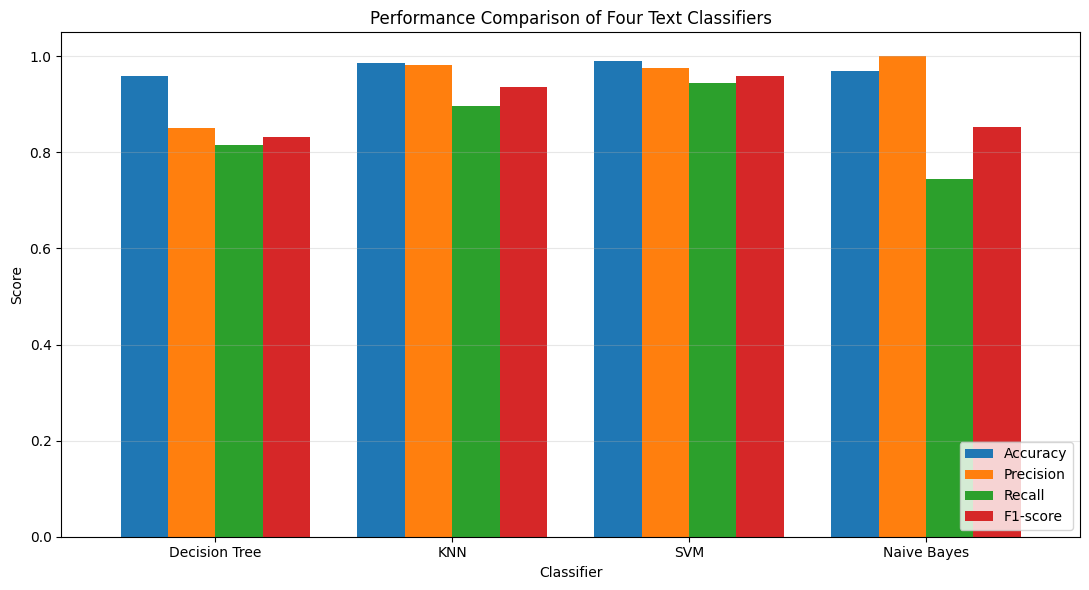

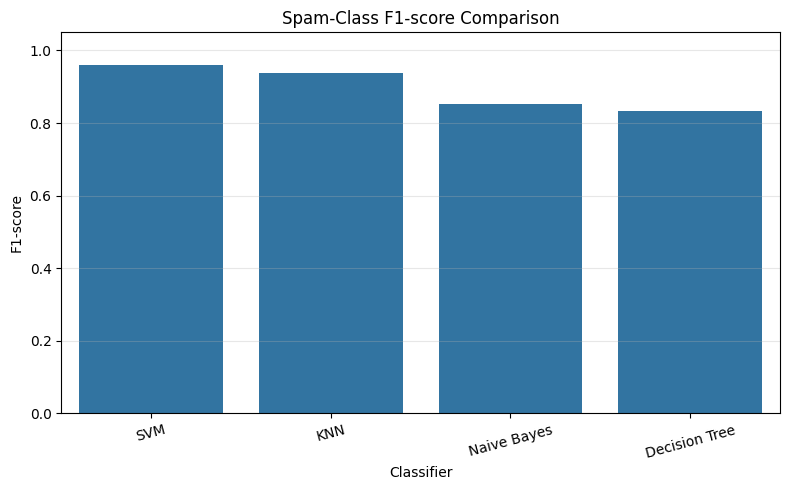

In [9]:
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

ax = results_df[metrics].plot(
    kind="bar",
    figsize=(11, 6),
    ylim=(0, 1.05),
    width=0.8
)
ax.set_title("Performance Comparison of Four Text Classifiers")
ax.set_xlabel("Classifier")
ax.set_ylabel("Score")
ax.legend(loc="lower right")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.barplot(
    data=comparison_table.reset_index(),
    x="Model",
    y="F1-score"
)
plt.ylim(0, 1.05)
plt.title("Spam-Class F1-score Comparison")
plt.xlabel("Classifier")
plt.ylabel("F1-score")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 11. Confusion matrix analysis

For each classifier, the confusion matrix uses this order:

- **True Negative (TN):** ham correctly classified as ham.
- **False Positive (FP):** ham incorrectly classified as spam.
- **False Negative (FN):** spam incorrectly classified as ham.
- **True Positive (TP):** spam correctly classified as spam.



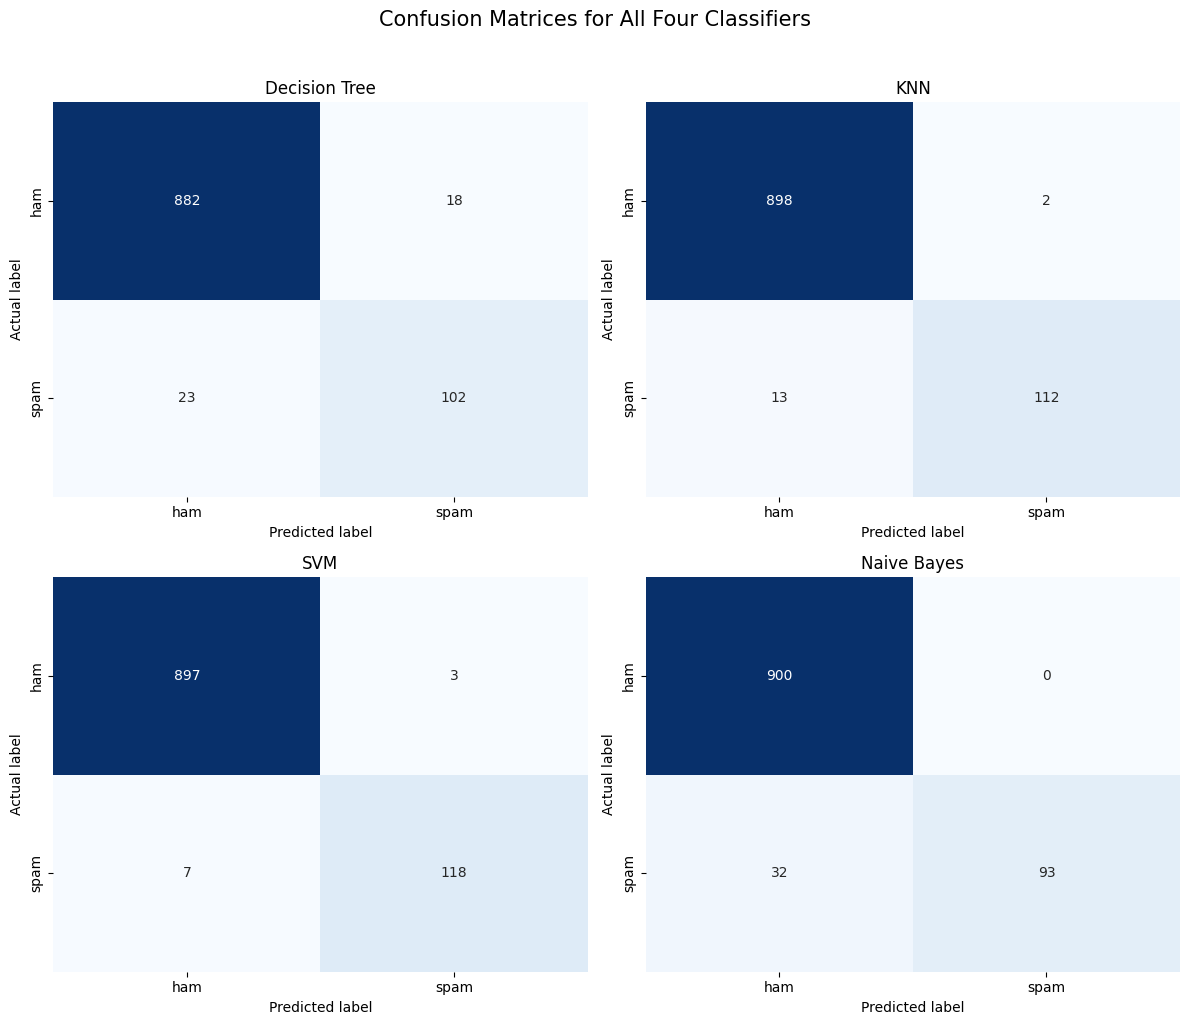

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for ax, (model_name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["ham", "spam"],
        yticklabels=["ham", "spam"],
        ax=ax
    )
    ax.set_title(model_name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")

plt.suptitle("Confusion Matrices for All Four Classifiers", y=1.02, fontsize=15)
plt.tight_layout()
plt.show()

In [ ]:
for model_name, y_pred in predictions.items():
    print("\n" + "=" * 60)
    print(model_name)
    print("=" * 60)
    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["ham", "spam"],
        zero_division=0,
        digits=4
    ))

,Accuracy,Precision,Recall,F1-score
SVM C,,,,
0.1,0.9776,1.0000,0.816,0.8987
1.0,0.9902,0.9752,0.944,0.9593
10.0,0.9893,0.9672,0.944,0.9555


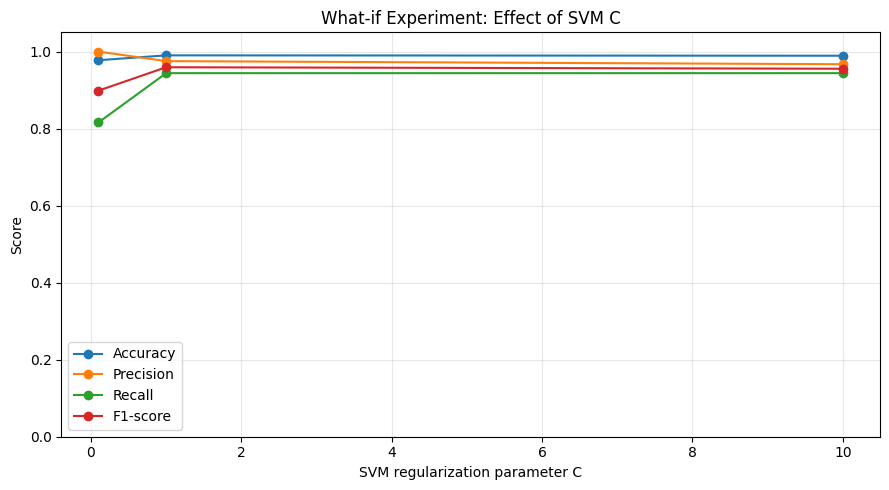

C value with the highest measured spam-class F1-score: 1.0
Corresponding F1-score: 0.9593


In [11]:
svm_c_values = [0.1, 1.0, 10.0]
what_if_results = []

for c_value in svm_c_values:
    svm_model = LinearSVC(
        C=c_value,
        random_state=RANDOM_STATE,
        max_iter=10000
    )
    svm_model.fit(X_train, y_train)
    svm_pred = svm_model.predict(X_test)

    what_if_results.append({
        "SVM C": c_value,
        "Accuracy": accuracy_score(y_test, svm_pred),
        "Precision": precision_score(y_test, svm_pred, pos_label=1, zero_division=0),
        "Recall": recall_score(y_test, svm_pred, pos_label=1, zero_division=0),
        "F1-score": f1_score(y_test, svm_pred, pos_label=1, zero_division=0)
    })

what_if_df = pd.DataFrame(what_if_results).set_index("SVM C")
display(what_if_df.round(4))

ax = what_if_df[["Accuracy", "Precision", "Recall", "F1-score"]].plot(
    marker="o",
    figsize=(9, 5)
)
ax.set_title("What-if Experiment: Effect of SVM C")
ax.set_xlabel("SVM regularization parameter C")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

best_c = what_if_df["F1-score"].idxmax()
print("C value with the highest measured spam-class F1-score:", best_c)
print("Corresponding F1-score:", round(what_if_df.loc[best_c, "F1-score"], 4))

In [12]:
best_row = results_df.loc[best_model_name]
print(f"Best classifier by spam F1-score: {best_model_name}")
print(f"Accuracy : {best_row['Accuracy']:.4f}")
print(f"Precision: {best_row['Precision']:.4f}")
print(f"Recall   : {best_row['Recall']:.4f}")
print(f"F1-score : {best_row['F1-score']:.4f}")

print("\nSVM what-if comparison:")
display(what_if_df.round(4))

best_svm_c = what_if_df["F1-score"].idxmax()
print(f"Best tested SVM C by F1-score: {best_svm_c}")

Best classifier by spam F1-score: SVM
Accuracy : 0.9902
Precision: 0.9752
Recall   : 0.9440
F1-score : 0.9593

SVM what-if comparison:


,Accuracy,Precision,Recall,F1-score
SVM C,,,,
0.1,0.9776,1.0000,0.816,0.8987
1.0,0.9902,0.9752,0.944,0.9593
10.0,0.9893,0.9672,0.944,0.9555


Best tested SVM C by F1-score: 1.0


In [13]:
results_df.to_csv("/content/classifier_comparison_results.csv")
what_if_df.to_csv("/content/svm_what_if_results.csv")

print("Saved files:")
print("/content/classifier_comparison_results.csv")
print("/content/svm_what_if_results.csv")

# In Google Colab, uncomment these lines if you want to download the CSV files:
# from google.colab import files
# files.download("/content/classifier_comparison_results.csv")
# files.download("/content/svm_what_if_results.csv")

Saved files:
/content/classifier_comparison_results.csv
/content/svm_what_if_results.csv
